In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

import warnings
warnings.filterwarnings('ignore')

# Random seed so every run gives the same result
RSEED = 50

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

## 1. Load and inspect the data

In [2]:
df = pd.read_csv('adult.csv')
print('Shape:', df.shape)
df.head()

Shape: (48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  capital-loss     48842 non-null  int64
 12  hours-per-week   48842 non-null  int64
 13  native-country   48842 non-null  str  
 14  income           48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [4]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [5]:
df.describe(include=['object', 'string'])

,workclass,education,marital-status,occupation,relationship,race,gender,native-country,income
count,48842,48842,48842,48842,48842,48842,48842,48842,48842
unique,9,16,7,15,6,5,2,42,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,33906,15784,22379,6172,19716,41762,32650,43832,37155


## 2. Data cleaning

### 2.1 Missing values
The dataset does not use empty cells for missing data. It uses the string `'?'` instead, so `isnull()` shows nothing until we replace it.

In [6]:
# Remove any leading/trailing spaces from text columns
cat_cols = df.select_dtypes(include=['object', 'string']).columns
for col in cat_cols:
    df[col] = df[col].str.strip()

print('Nulls before replacing "?":', df.isnull().sum().sum())
print('\n"?" count per column:')
print((df == '?').sum()[lambda s: s > 0])

Nulls before replacing "?": 0

"?" count per column:
workclass         2799
occupation        2809
native-country     857
dtype: int64


In [7]:
df = df.replace('?', np.nan)

missing = pd.DataFrame({'missing': df.isnull().sum(),
                        'percent': (df.isnull().mean() * 100).round(2)})
missing[missing['missing'] > 0]

,missing,percent
workclass,2799,5.73
occupation,2809,5.75
native-country,857,1.75


In [8]:
# Are workclass and occupation missing for the same people?
both = (df['workclass'].isnull() & df['occupation'].isnull()).sum()
print(f'Rows missing workclass: {df["workclass"].isnull().sum()}')
print(f'Rows missing occupation: {df["occupation"].isnull().sum()}')
print(f'Rows missing both:       {both}')

# Does missing data relate to income?
print('\nShare earning >50K:')
print('  rows with missing occupation:', round((df.loc[df['occupation'].isnull(), 'income'] == '>50K').mean(), 3))
print('  all rows:                    ', round((df['income'] == '>50K').mean(), 3))

Rows missing workclass: 2799
Rows missing occupation: 2809
Rows missing both:       2799

Share earning >50K:
  rows with missing occupation: 0.094
  all rows:                     0.239


All 2,799 rows missing `workclass` are also missing `occupation`, and people with missing occupation earn >50K only 9% of the time versus 24% overall (they are mostly not working).
So "missing" carries information. Instead of dropping ~7% of rows or guessing with the mode, we put them in their own category **`Unknown`**.

In [9]:
for col in ['workclass', 'occupation', 'native-country']:
    df[col] = df[col].fillna('Unknown')

print('Missing values left:', df.isnull().sum().sum())

Missing values left: 0


### 2.2 Duplicate rows

In [10]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

Duplicate rows: 52


Shape after dropping duplicates: (48790, 15)


### 2.3 Redundant columns
`education` (text) and `educational-num` (number) should describe the same thing. Check that each education level maps to exactly one number.

In [11]:
df.groupby('education')['educational-num'].unique().sort_values()

education
Preschool        [1]
1st-4th          [2]
5th-6th          [3]
7th-8th          [4]
9th              [5]
10th             [6]
11th             [7]
12th             [8]
HS-grad          [9]
Some-college    [10]
Assoc-voc       [11]
Assoc-acdm      [12]
Bachelors       [13]
Masters         [14]
Prof-school     [15]
Doctorate       [16]
Name: educational-num, dtype: object

Each level maps to one number, so `education` is redundant. We keep `educational-num` because it is already ordered (higher = more education).

In [12]:
df = df.drop(columns=['education'])

### 2.4 Target column
Convert `income` to 0/1: `0` = <=50K, `1` = >50K.

In [13]:
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})
df['income'].value_counts()

income
0    37109
1    11681
Name: count, dtype: int64

### 2.5 Outliers
Check the numeric columns with box plots.

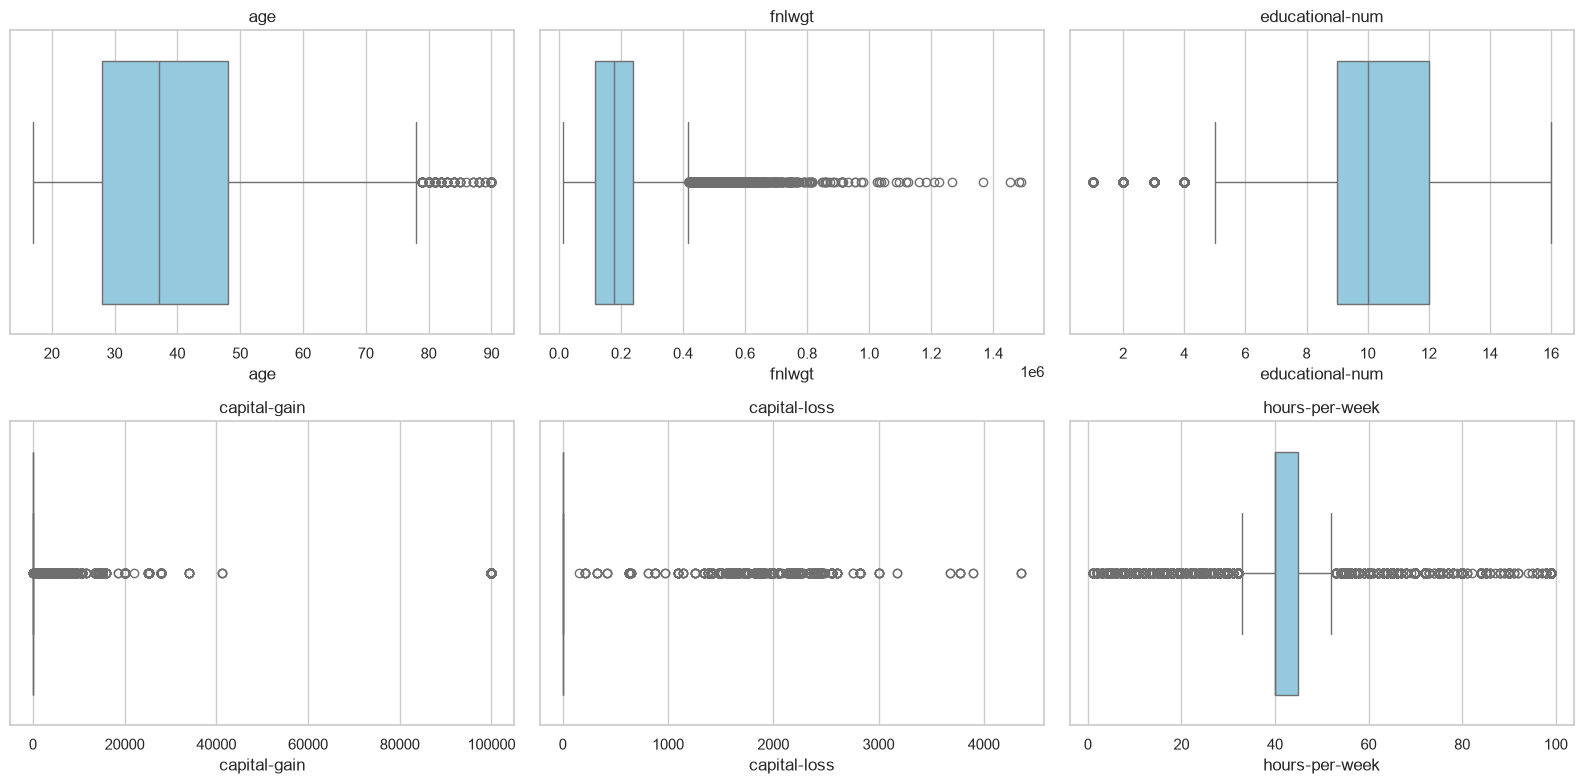

In [14]:
num_cols = ['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [15]:
print('capital-gain = 0:', round((df['capital-gain'] == 0).mean() * 100, 1), '%')
print('capital-loss = 0:', round((df['capital-loss'] == 0).mean() * 100, 1), '%')
print('capital-gain = 99999 (cap value):', (df['capital-gain'] == 99999).sum(), 'rows')
print('\nIncome rate for capital-gain = 99999:', df.loc[df['capital-gain'] == 99999, 'income'].mean())

capital-gain = 0: 91.7 %
capital-loss = 0: 95.3 %
capital-gain = 99999 (cap value): 244 rows

Income rate for capital-gain = 99999: 1.0


- `capital-gain` and `capital-loss` are zero for over 90% of people, so most "outliers" are just the few people with investments.
- `99999` is a cap value, but everyone with it earns >50K, so it is real signal.
- Ages up to 90 and hours up to 99 are plausible.

Decision trees split on thresholds, so they are not affected by outliers or feature scale. **We keep the outliers and do not scale.**

In [16]:
print('Clean data shape:', df.shape)
df.head()

Clean data shape: (48790, 14)


,age,workclass,fnlwgt,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,0
1,38,Private,89814,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,0
2,28,Local-gov,336951,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,1
3,44,Private,160323,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,1
4,18,Unknown,103497,10,Never-married,Unknown,Own-child,White,Female,0,0,30,United-States,0


## 3.  EDA and Visualisation

### 3.1 Target distribution

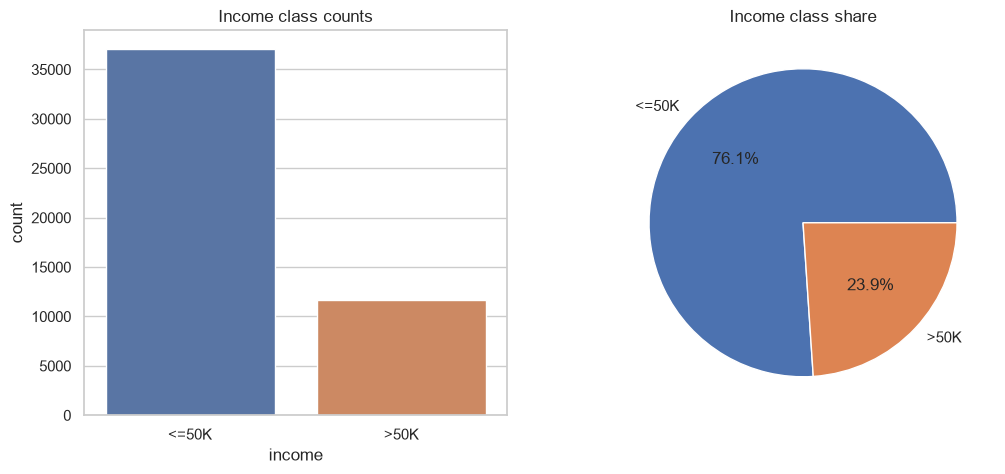

In [17]:
counts = df['income'].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x='income', data=df, ax=ax[0], palette=['#4C72B0', '#DD8452'])
ax[0].set_xticklabels(['<=50K', '>50K'])
ax[0].set_title('Income class counts')
ax[1].pie(counts, labels=['<=50K', '>50K'], autopct='%1.1f%%', colors=['#4C72B0', '#DD8452'])
ax[1].set_title('Income class share')
plt.show()

The classes are **imbalanced** (about 76% vs 24%). A model that always predicts <=50K would already get ~76% accuracy,
so like the tutorial we also look at **precision, recall, F1 and ROC AUC**, not just accuracy.

### 3.2 Numeric features

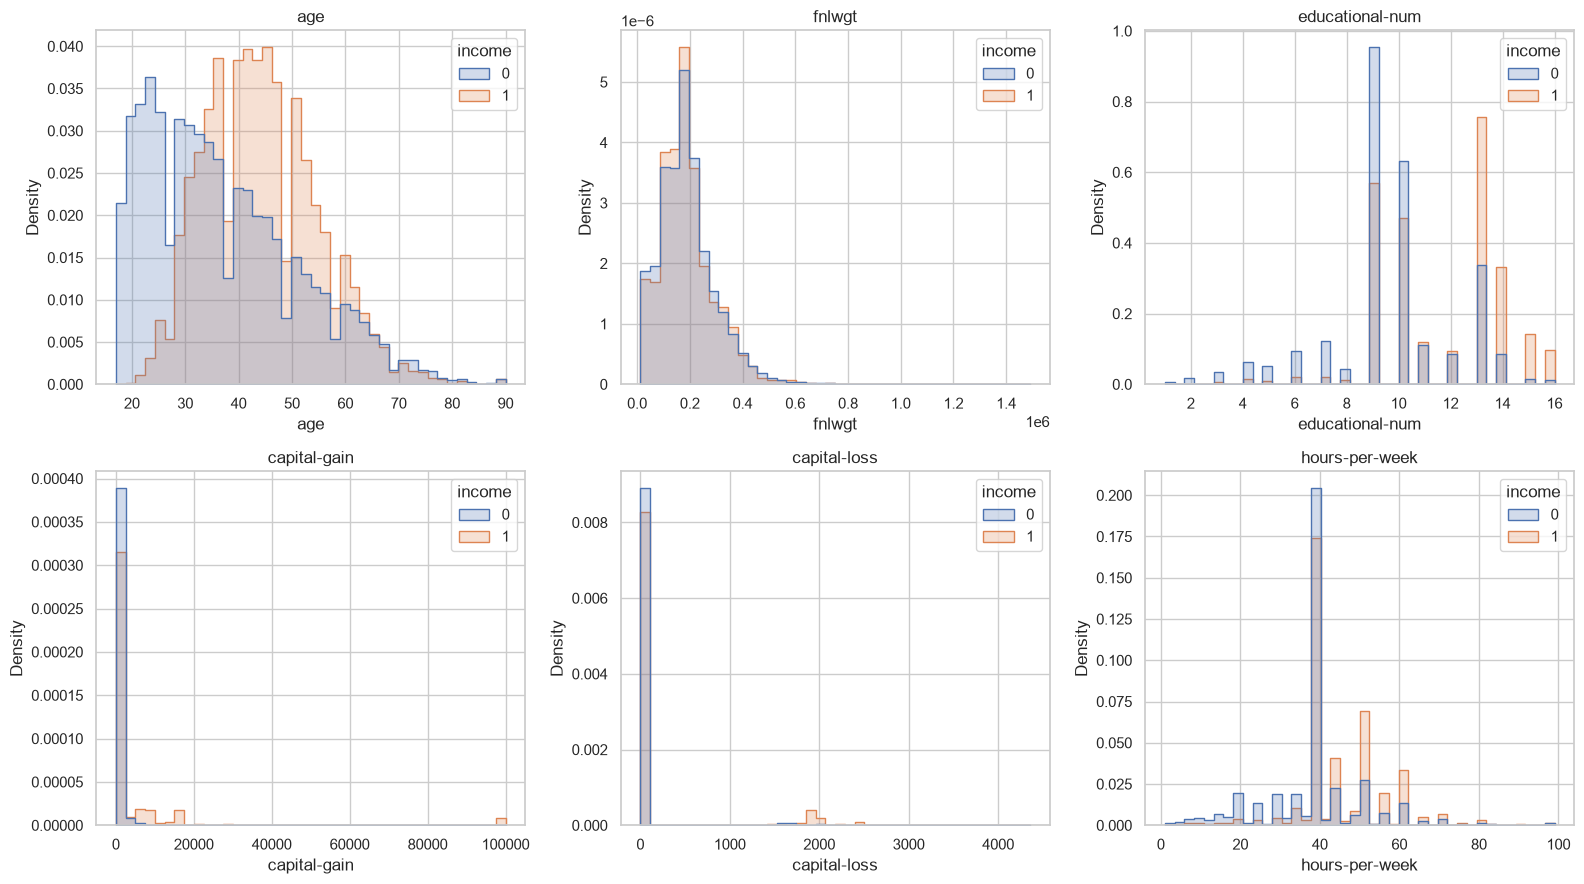

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue='income', bins=40, ax=ax, element='step', stat='density', common_norm=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

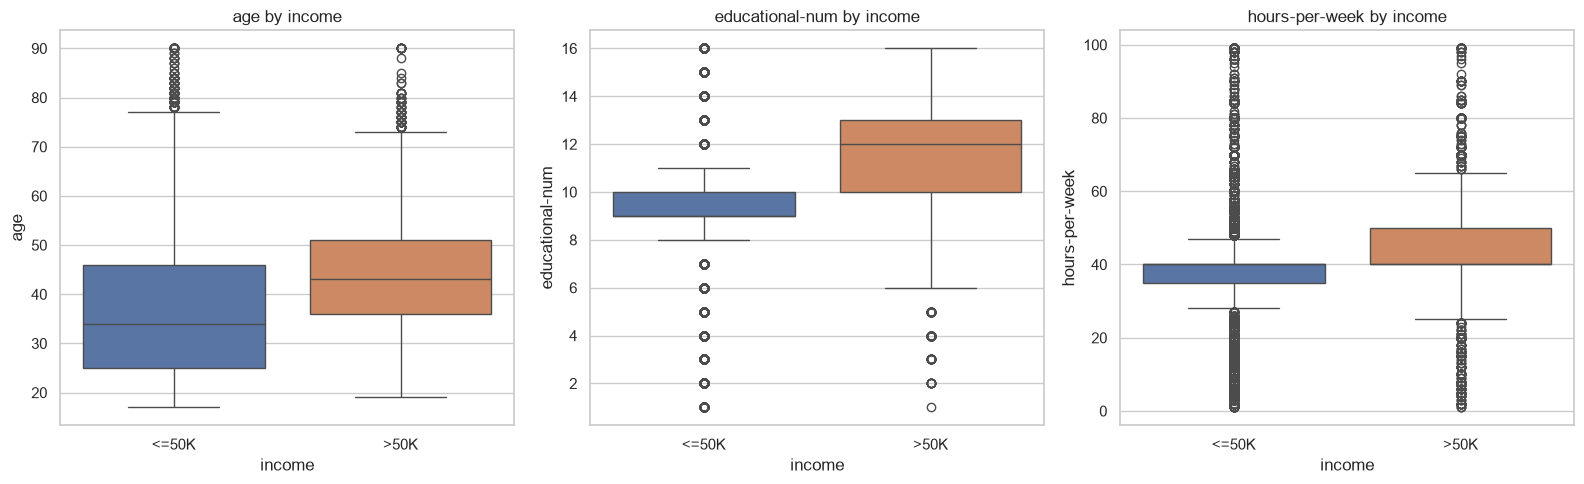

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
income,,,,,,
0,36.9,190042.8,9.6,147.2,54.2,38.8
1,44.3,188481.4,11.6,4044.3,193.6,45.5


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['age', 'educational-num', 'hours-per-week']):
    sns.boxplot(data=df, x='income', y=col, ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.set_xticklabels(['<=50K', '>50K'])
    ax.set_title(f'{col} by income')
plt.tight_layout()
plt.show()

df.groupby('income')[num_cols].mean().round(1)

- People earning >50K are **older** (average ~44 vs ~37), have **more education** and work **more hours** per week.
- `fnlwgt` looks the same for both classes, which makes sense because it is a census sampling weight, not a personal attribute.

### 3.3 Correlation between numeric features

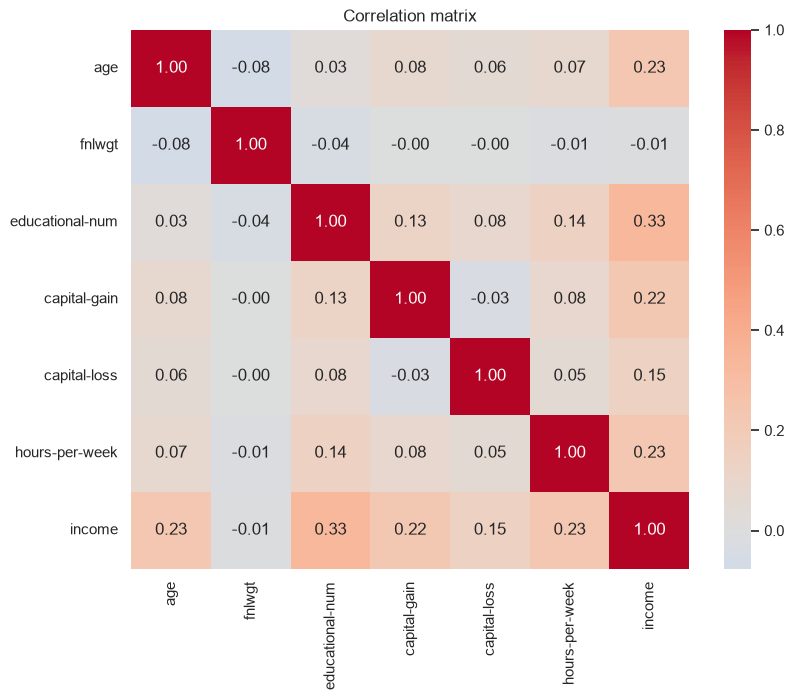

In [20]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols + ['income']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

No two numeric features are strongly correlated with each other, so there is no multicollinearity problem.
`educational-num`, `age`, `hours-per-week` and `capital-gain` have the strongest relationship with income, and `fnlwgt` has almost none.

### 3.4 Categorical features: share earning >50K

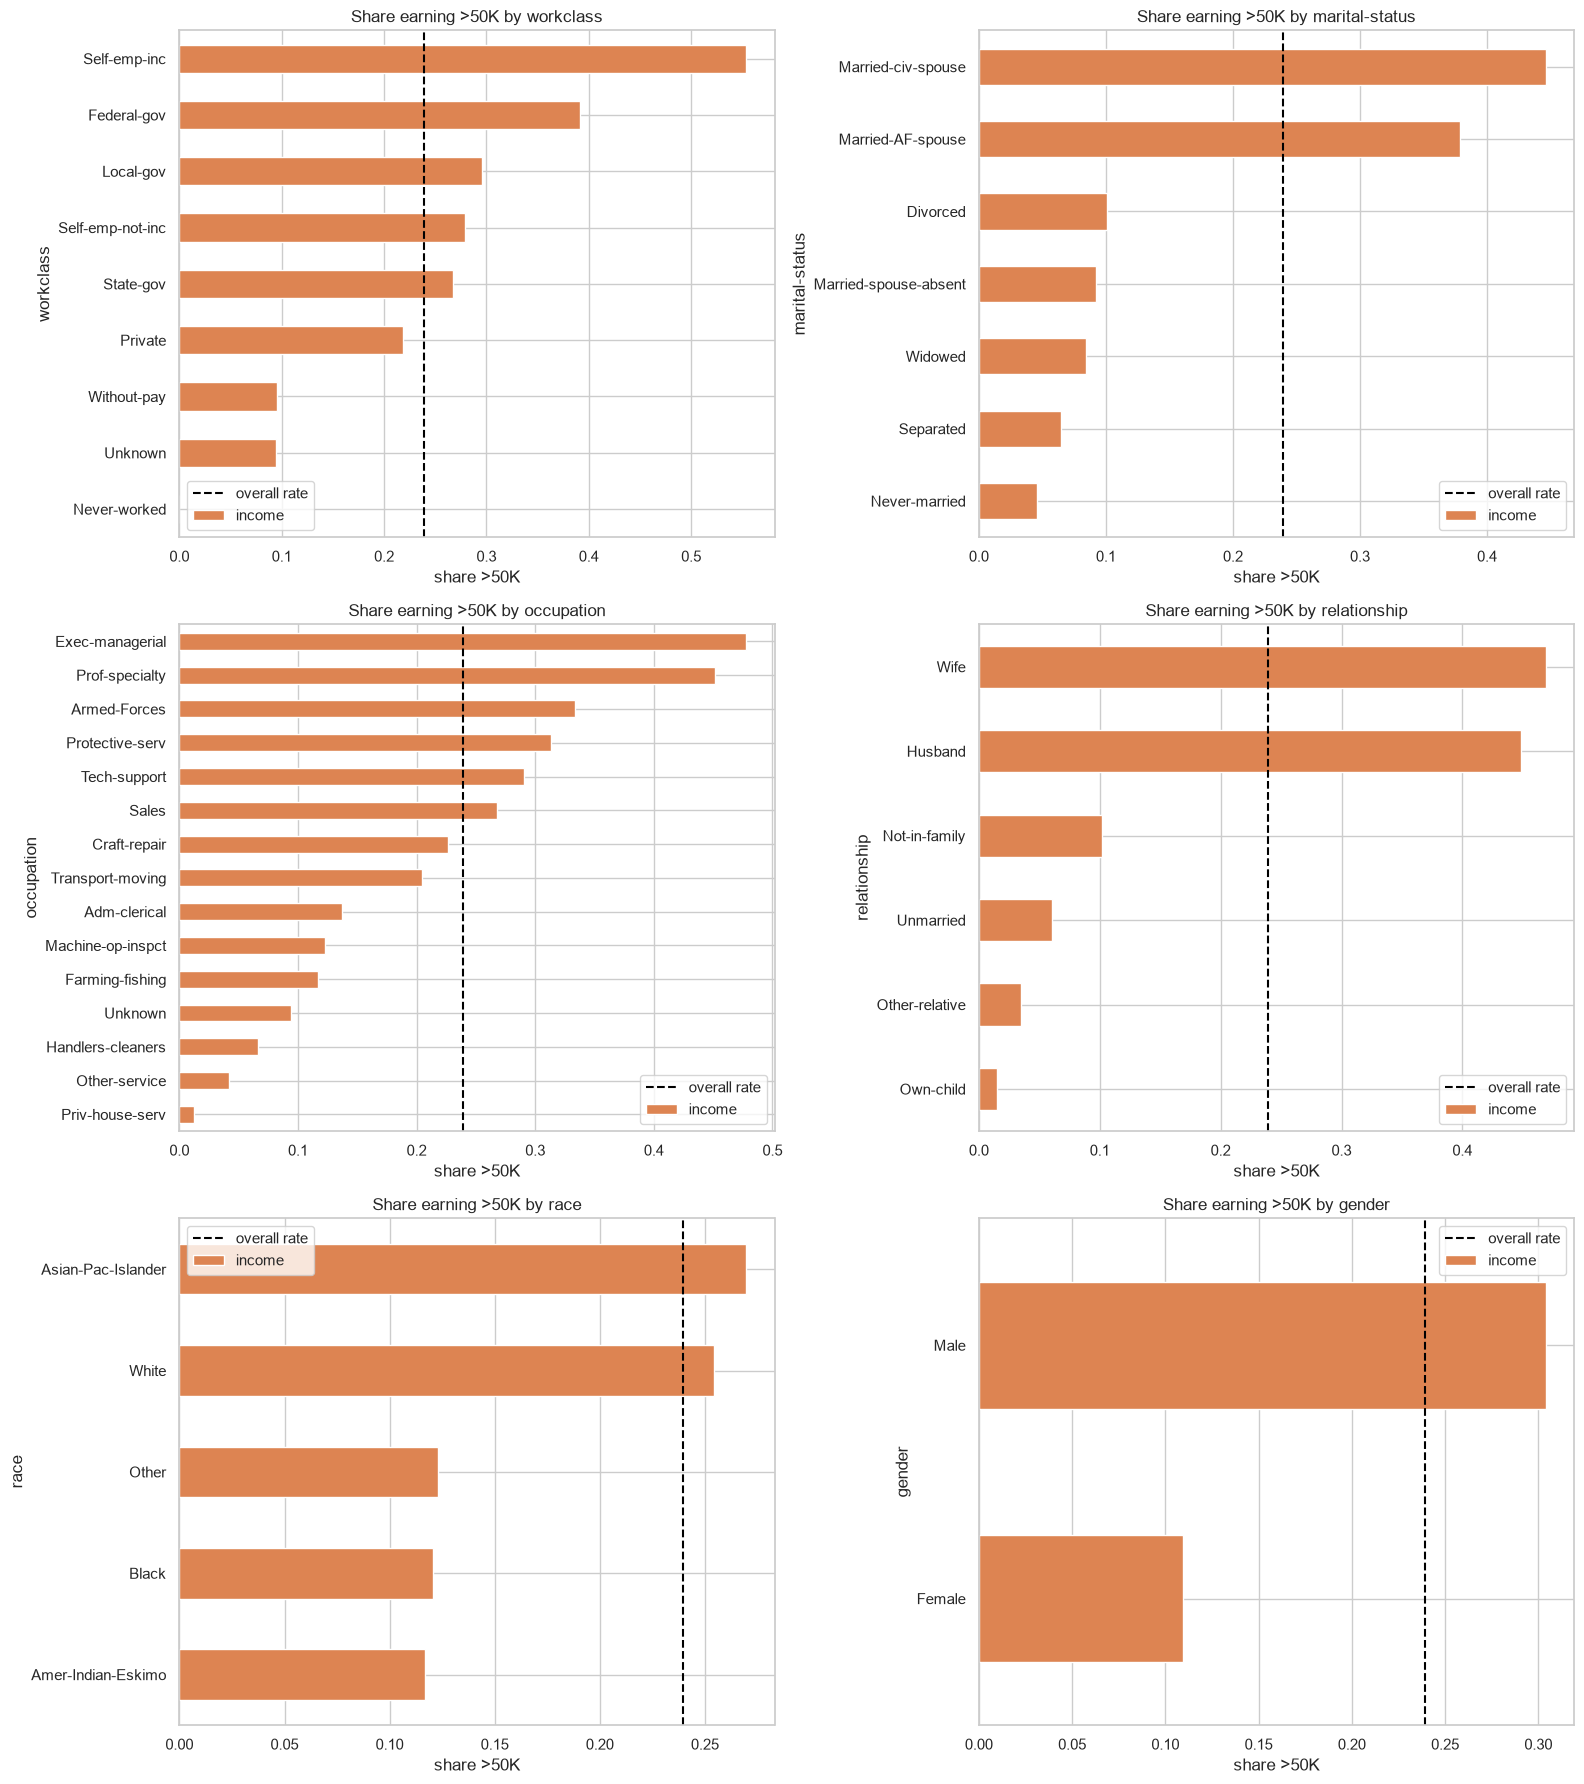

In [21]:
cat_features = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'gender']

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
for ax, col in zip(axes.ravel(), cat_features):
    rate = df.groupby(col)['income'].mean().sort_values()
    rate.plot(kind='barh', ax=ax, color='#DD8452')
    ax.axvline(df['income'].mean(), color='black', linestyle='--', label='overall rate')
    ax.set_title(f'Share earning >50K by {col}')
    ax.set_xlabel('share >50K')
    ax.legend()
plt.tight_layout()
plt.show()

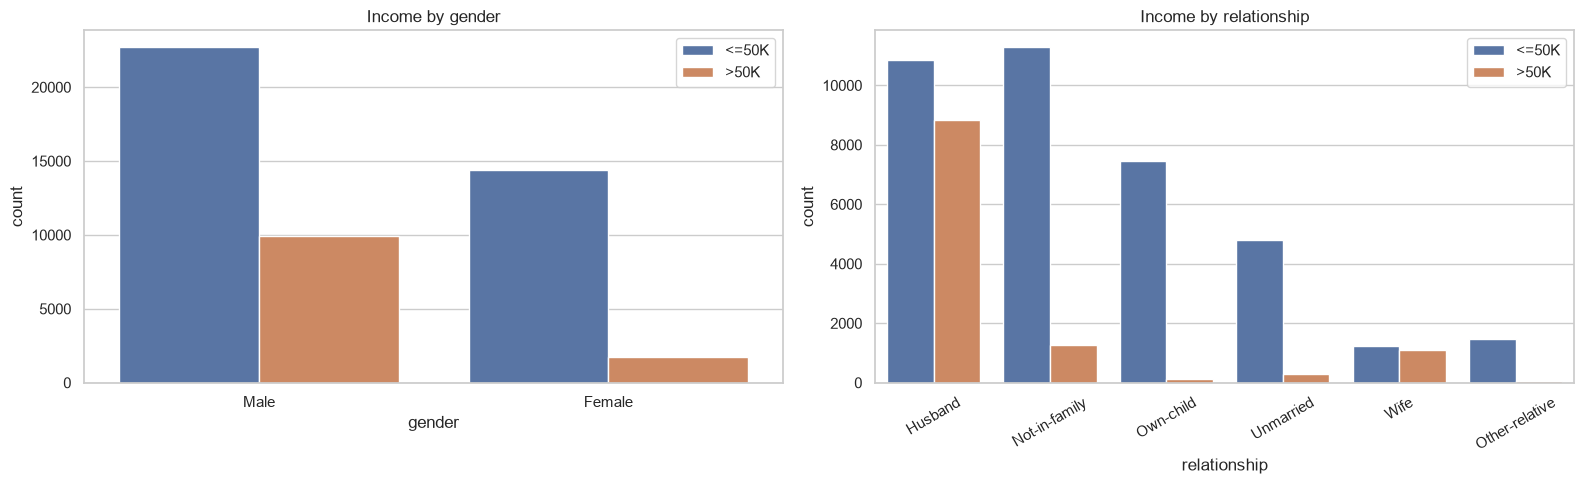

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=df, x='gender', hue='income', ax=axes[0])
axes[0].set_title('Income by gender')
axes[0].legend(['<=50K', '>50K'])
order = df['relationship'].value_counts().index
sns.countplot(data=df, x='relationship', hue='income', order=order, ax=axes[1])
axes[1].set_title('Income by relationship')
axes[1].legend(['<=50K', '>50K'])
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

- **Marital status / relationship** is the strongest split: married people (Husband/Wife) earn >50K about 45% of the time, while never-married people and own-children rarely do.
- **Occupation**: Exec-managerial and Prof-specialty have the highest rate; Private house service and Handlers-cleaners the lowest. The `Unknown` group is well below average, which supports keeping it as its own category.
- **Gender**: about 30% of men earn >50K versus about 11% of women.
- **Workclass**: Self-employed (incorporated) has the highest rate.

### 3.5 Education and age together (Feat Engineering)

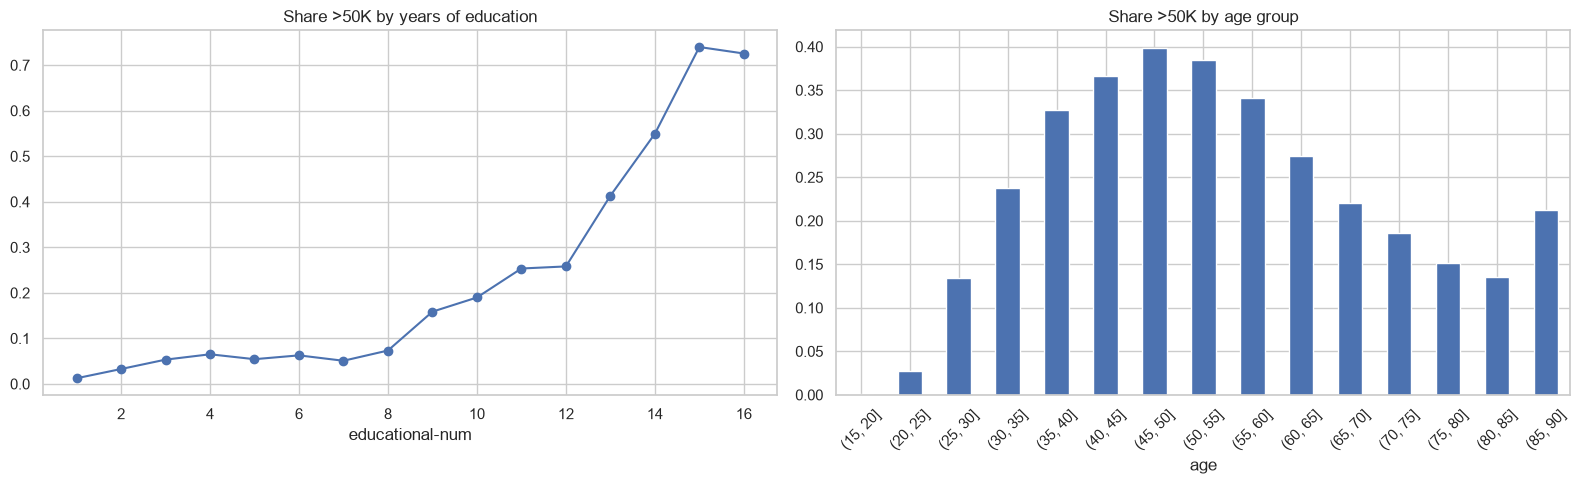

In [23]:
edu_rate = df.groupby('educational-num')['income'].mean()
age_rate = df.groupby(pd.cut(df['age'], bins=range(15, 95, 5)))['income'].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
edu_rate.plot(marker='o', ax=axes[0])
axes[0].set_title('Share >50K by years of education')
axes[0].set_xlabel('educational-num')
age_rate.plot(kind='bar', ax=axes[1], color='#4C72B0')
axes[1].set_title('Share >50K by age group')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

The chance of earning >50K rises steadily with education, and with age up to about 45–55 before falling again near retirement.

### 3.6 Native country

In [24]:
top = df['native-country'].value_counts().head(10)
print(top)
print('\nShare from United-States:', round((df['native-country'] == 'United-States').mean() * 100, 1), '%')

native-country
United-States    43792
Mexico             943
Unknown            856
Philippines        294
Germany            206
Puerto-Rico        184
Canada             182
El-Salvador        155
India              151
Cuba               138
Name: count, dtype: int64

Share from United-States: 89.8 %


About 90% of people are from the United States, so this feature adds little. We keep it; the one-hot columns for rare countries will just get low importance.

## 4. Preprocessing

- Drop `fnlwgt`: it is a census sampling weight, not a property of the person, and the EDA shows no relationship with income.
- **One-hot encode** the categorical columns. Trees can split on each category separately, and one-hot avoids inventing a fake order between categories.
- No scaling: tree models do not need it.
- **Stratified 70/30 split** so the train and test sets keep the same 76/24 class ratio (same as the tutorial).

In [25]:
data = df.drop(columns=['fnlwgt'])

cat_cols = data.select_dtypes(include=['object', 'string']).columns.tolist()
print('Categorical columns:', cat_cols)

data = pd.get_dummies(data, columns=cat_cols, dtype=int)
print('Shape after one-hot encoding:', data.shape)

Categorical columns: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country']
Shape after one-hot encoding: (48790, 92)


In [26]:
y = data.pop('income').values
X = data
features = list(X.columns)

train, test, train_labels, test_labels = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RSEED)

print('Train:', train.shape, ' Test:', test.shape)
print('Share >50K  train:', round(train_labels.mean(), 3), ' test:', round(test_labels.mean(), 3))

Train: (34153, 91)  Test: (14637, 91)
Share >50K  train: 0.239  test: 0.239


### Evaluation helpers
Based on the tutorial's `evaluate_model`, extended with accuracy and F1, and returning the scores so we can compare models at the end.
The baseline always predicts the majority class (<=50K).

In [27]:
results = {}

def evaluate_model(name, model):
    """Print train vs test metrics, plot ROC curve and confusion matrix, and store the test scores."""
    train_pred = model.predict(train)
    train_prob = model.predict_proba(train)[:, 1]
    test_pred = model.predict(test)
    test_prob = model.predict_proba(test)[:, 1]

    scores = pd.DataFrame({
        'Train': [accuracy_score(train_labels, train_pred), precision_score(train_labels, train_pred),
                  recall_score(train_labels, train_pred), f1_score(train_labels, train_pred),
                  roc_auc_score(train_labels, train_prob)],
        'Test':  [accuracy_score(test_labels, test_pred), precision_score(test_labels, test_pred),
                  recall_score(test_labels, test_pred), f1_score(test_labels, test_pred),
                  roc_auc_score(test_labels, test_prob)],
    }, index=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']).round(3)
    print(name)
    print(scores)
    results[name] = scores['Test']

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    fpr, tpr, _ = roc_curve(test_labels, test_prob)
    axes[0].plot([0, 1], [0, 1], 'b--', label='baseline (AUC = 0.5)')
    axes[0].plot(fpr, tpr, 'r', label=f'model (AUC = {scores.loc["ROC AUC", "Test"]})')
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'ROC curve: {name}')
    axes[0].legend()

    cm = confusion_matrix(test_labels, test_pred)
    ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot(ax=axes[1], cmap='Oranges', values_format='d')
    axes[1].set_title(f'Confusion matrix: {name}')
    axes[1].grid(False)
    plt.tight_layout()
    plt.show()
    return test_prob

def plot_importances(model, title, n=15):
    fi = pd.DataFrame({'feature': features, 'importance': model.feature_importances_}) \
           .sort_values('importance', ascending=False).head(n)
    plt.figure(figsize=(10, 6))
    sns.barplot(data=fi, x='importance', y='feature', color='#4C72B0')
    plt.title(title)
    plt.show()
    return fi

# Baseline: always predict the majority class
baseline_pred = np.zeros(len(test_labels))
print('Baseline accuracy (always <=50K):', round(accuracy_score(test_labels, baseline_pred), 3))
print('Baseline recall for >50K:        ', recall_score(test_labels, baseline_pred))

Baseline accuracy (always <=50K): 0.761
Baseline recall for >50K:         0.0


## 5. Decision Tree

### 5.1 Unlimited depth
As in the tutorial, first let the tree grow as deep as it wants. We expect it to memorise the training data.

In [28]:
tree = DecisionTreeClassifier(random_state=RSEED)
tree.fit(train, train_labels)
print(f'Decision tree has {tree.tree_.node_count} nodes with maximum depth {tree.tree_.max_depth}.')

Decision tree has 11883 nodes with maximum depth 49.


Decision Tree (unlimited)
           Train   Test
Accuracy   0.976  0.820
Precision  0.980  0.627
Recall     0.920  0.613
F1         0.949  0.620
ROC AUC    0.998  0.774


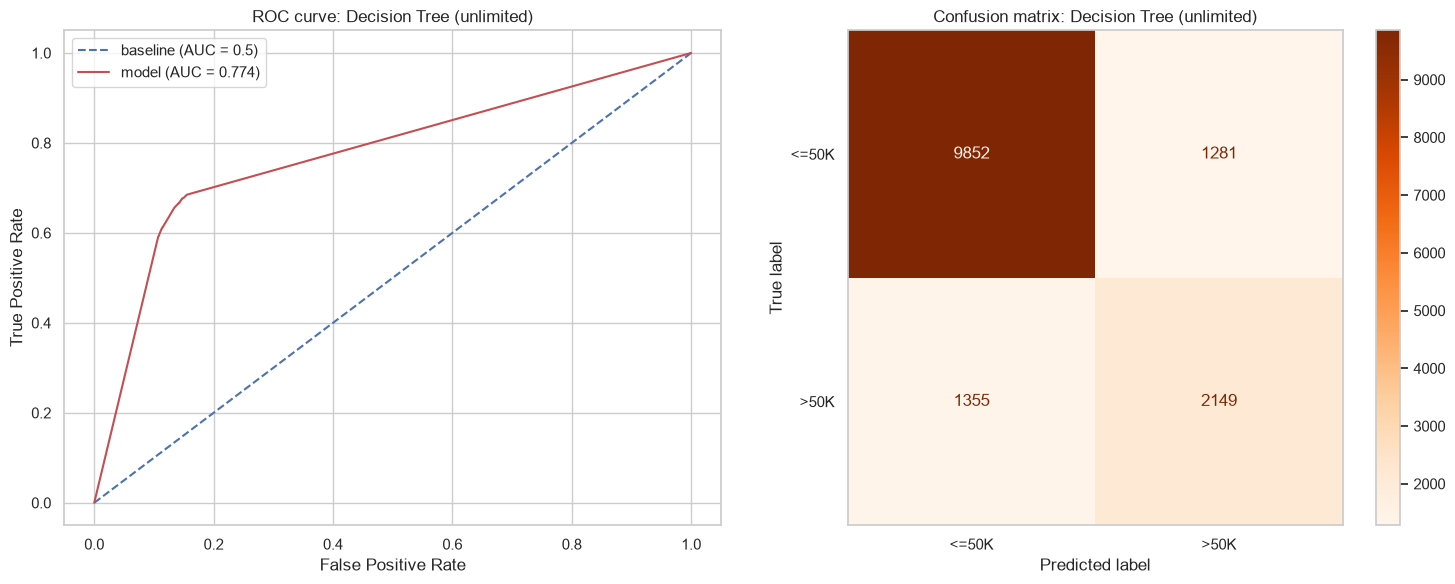

In [29]:
probs = {}
probs['Decision Tree (unlimited)'] = evaluate_model('Decision Tree (unlimited)', tree)

Train scores are almost perfect but the test scores are clearly lower. The tree has **overfit**: it learned noise in the training data that does not carry over to new people.

### 5.2 Tuned Decision Tree
Limit the tree's complexity. `GridSearchCV` tries every combination with 5-fold cross-validation on the training set only, scoring by ROC AUC.

In [30]:
dt_grid = {
    'max_depth': [4, 6, 8, 10, 12, 15],
    'min_samples_leaf': [1, 10, 25, 50],
    'criterion': ['gini', 'entropy'],
}
dt_search = GridSearchCV(DecisionTreeClassifier(random_state=RSEED), dt_grid,
                         scoring='roc_auc', cv=5, n_jobs=-1)
dt_search.fit(train, train_labels)

print('Best parameters:', dt_search.best_params_)
print('Best CV ROC AUC:', round(dt_search.best_score_, 3))

best_tree = dt_search.best_estimator_
print(f'Tuned tree has {best_tree.tree_.node_count} nodes with maximum depth {best_tree.tree_.max_depth}.')

Best parameters: {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 50}
Best CV ROC AUC: 0.906
Tuned tree has 645 nodes with maximum depth 15.


Decision Tree (tuned)
           Train   Test
Accuracy   0.865  0.858
Precision  0.780  0.756
Recall     0.611  0.601
F1         0.685  0.670
ROC AUC    0.922  0.907


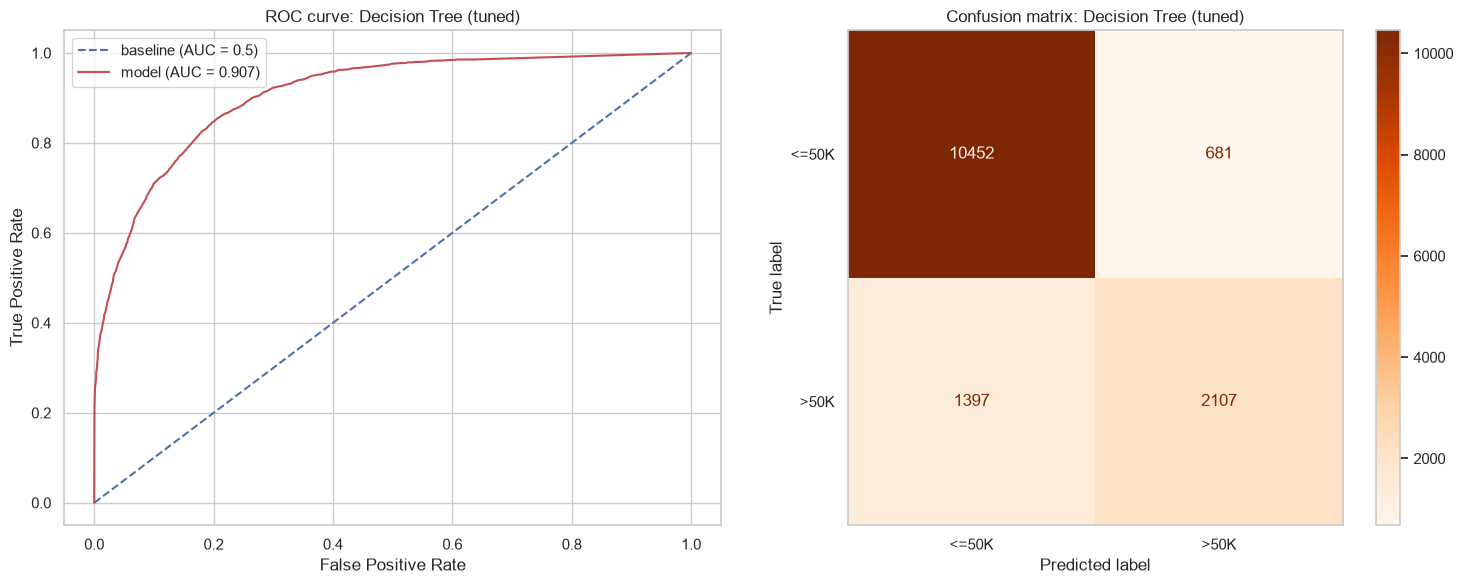

In [31]:
probs['Decision Tree (tuned)'] = evaluate_model('Decision Tree (tuned)', best_tree)

Train and test scores are now close, so the tuned tree generalises much better, and its test ROC AUC is much higher than the unlimited tree's.

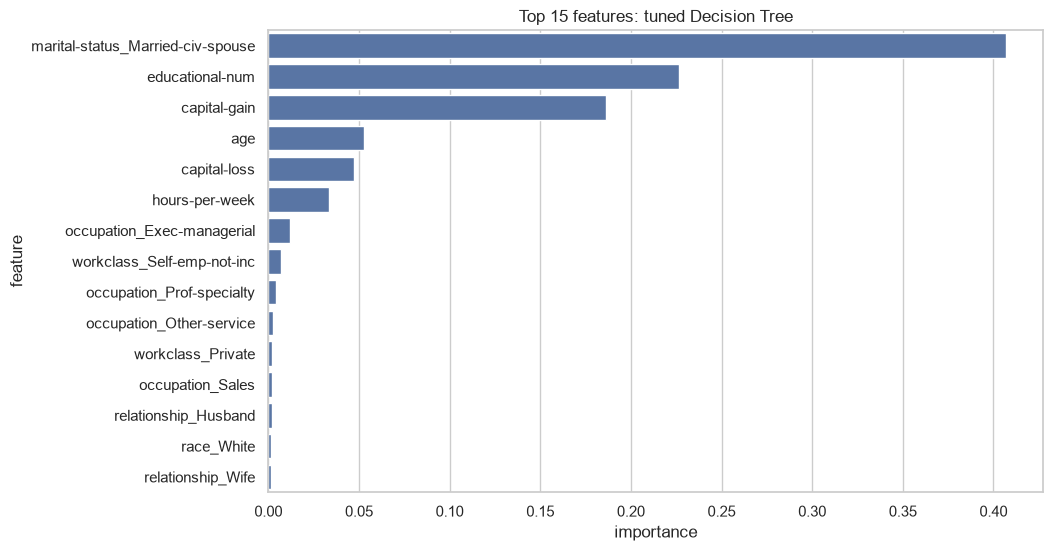

,feature,importance
16,marital-status_Married-civ-spouse,0.407177
1,educational-num,0.226514
2,capital-gain,0.186373
0,age,0.052520
3,capital-loss,0.047022
4,hours-per-week,0.033709
24,occupation_Exec-managerial,0.011903
10,workclass_Self-emp-not-inc,0.007011
30,occupation_Prof-specialty,0.004242
28,occupation_Other-service,0.002574


In [32]:
fi_tree = plot_importances(best_tree, 'Top 15 features: tuned Decision Tree')
fi_tree

### 5.3 Visualize the tree
The tutorial used Graphviz. `plot_tree` from scikit-learn draws the same thing without installing anything extra. Only the top 3 levels are shown so it stays readable.

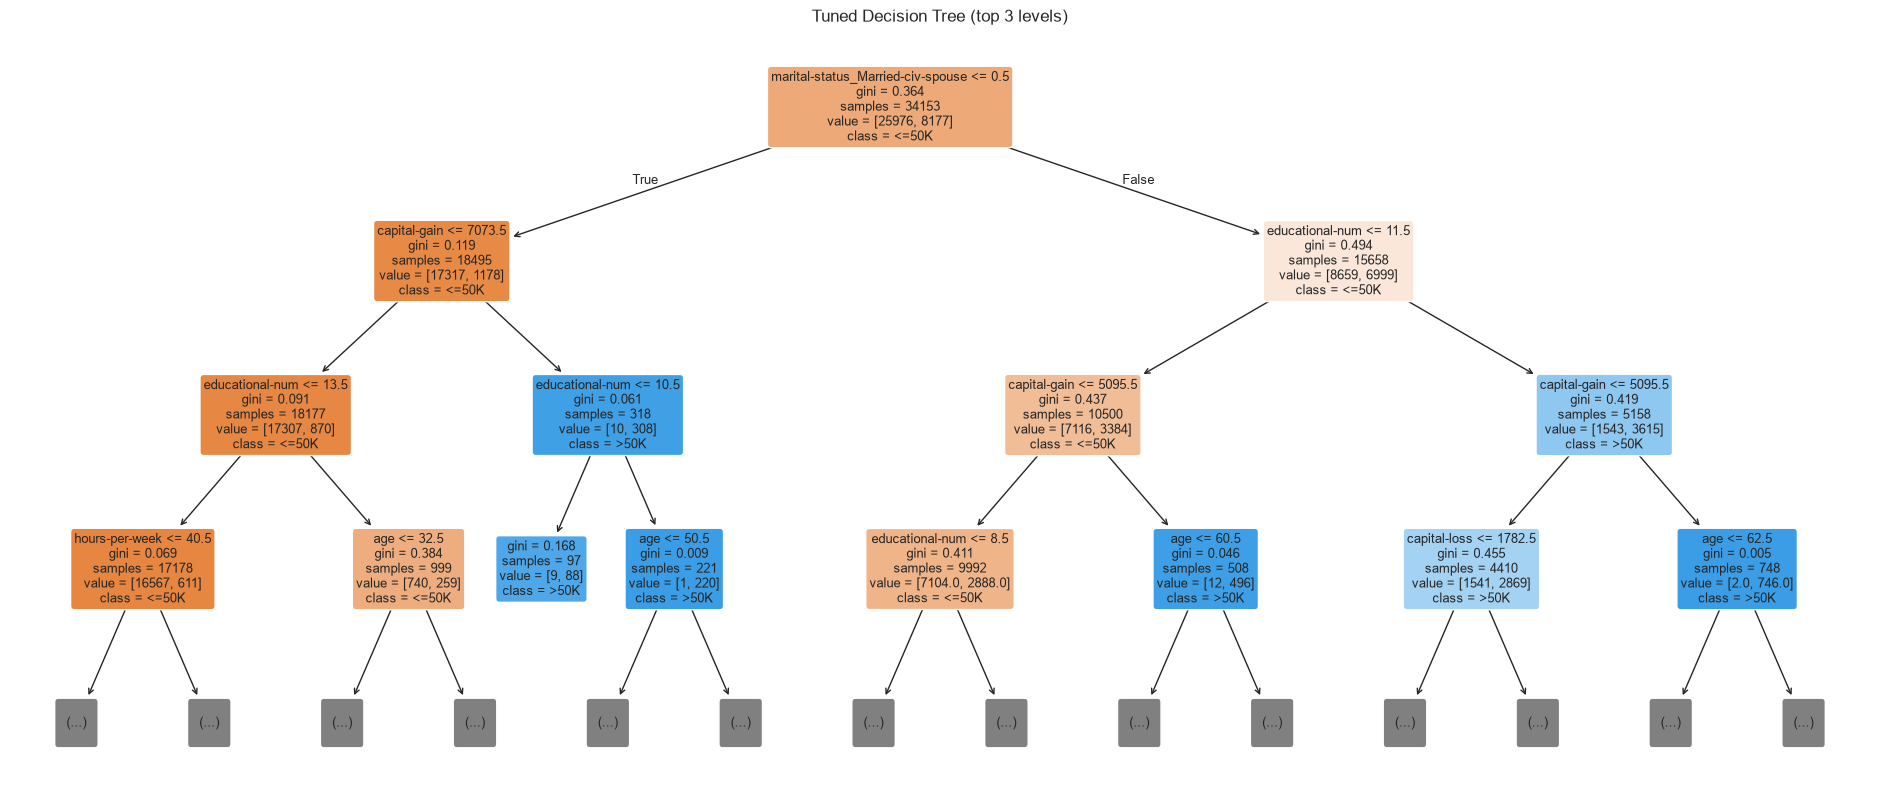

In [33]:
plt.figure(figsize=(24, 10))
plot_tree(best_tree, max_depth=3, feature_names=features, class_names=['<=50K', '>50K'],
          filled=True, rounded=True, fontsize=9)
plt.title('Tuned Decision Tree (top 3 levels)')
plt.show()

The first split is on `marital-status_Married-civ-spouse`, matching the EDA. Married people are then split mostly by education and capital gain, and unmarried people by capital gain and education.

## 6. Random Forest

### 6.1 Default Random Forest (100 trees)
Each tree is trained on a bootstrap sample of the rows and considers only a random subset of features (`sqrt`) at each split. The forest averages their votes, which reduces variance.

In [34]:
rf = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=RSEED, n_jobs=-1)
rf.fit(train, train_labels)

n_nodes = [t.tree_.node_count for t in rf.estimators_]
max_depths = [t.tree_.max_depth for t in rf.estimators_]
print(f'Average number of nodes {int(np.mean(n_nodes))}')
print(f'Average maximum depth {int(np.mean(max_depths))}')

Average number of nodes 11765
Average maximum depth 53


Random Forest (default)
           Train   Test
Accuracy   0.976  0.847
Precision  0.957  0.706
Recall     0.944  0.617
F1         0.950  0.658
ROC AUC    0.997  0.892


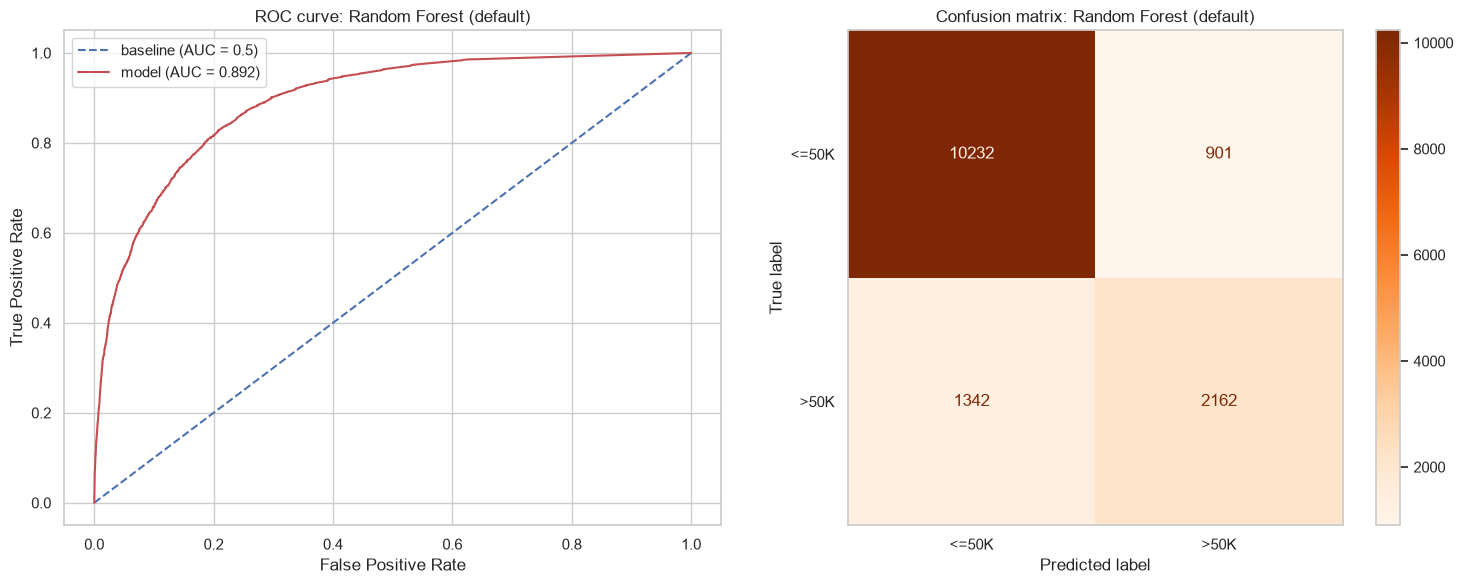

In [35]:
probs['Random Forest (default)'] = evaluate_model('Random Forest (default)', rf)

Like in the tutorial, each tree is fully grown so the train scores are near perfect, but averaging 100 trees gives a much better test ROC AUC than the unlimited single tree.

### 6.2 Tuned Random Forest (random search)
Same idea as the tutorial's `RandomizedSearchCV`. Note: `max_features='auto'` from the tutorial no longer exists in recent scikit-learn, so we use `'sqrt'`, `'log2'` and fractions.

In [36]:
rf_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 15, 20, 25],
    'max_features': ['sqrt', 'log2', 0.3, 0.5],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'bootstrap': [True, False],
}
rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=RSEED, n_jobs=-1), rf_grid,
                               n_iter=20, scoring='roc_auc', cv=3, random_state=RSEED, n_jobs=-1, verbose=1)
rf_search.fit(train, train_labels)

print('Best parameters:', rf_search.best_params_)
print('Best CV ROC AUC:', round(rf_search.best_score_, 3))
best_rf = rf_search.best_estimator_

Fitting 3 folds for each of 20 candidates, totalling 60 fits


Best parameters: {'n_estimators': 200, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 25, 'bootstrap': True}
Best CV ROC AUC: 0.919


In [37]:
n_nodes = [t.tree_.node_count for t in best_rf.estimators_]
max_depths = [t.tree_.max_depth for t in best_rf.estimators_]
print(f'Average number of nodes {int(np.mean(n_nodes))}')
print(f'Average maximum depth {int(np.mean(max_depths))}')

Average number of nodes 2326
Average maximum depth 25


Random Forest (tuned)
           Train   Test
Accuracy   0.898  0.866
Precision  0.852  0.770
Recall     0.693  0.630
F1         0.764  0.693
ROC AUC    0.959  0.918


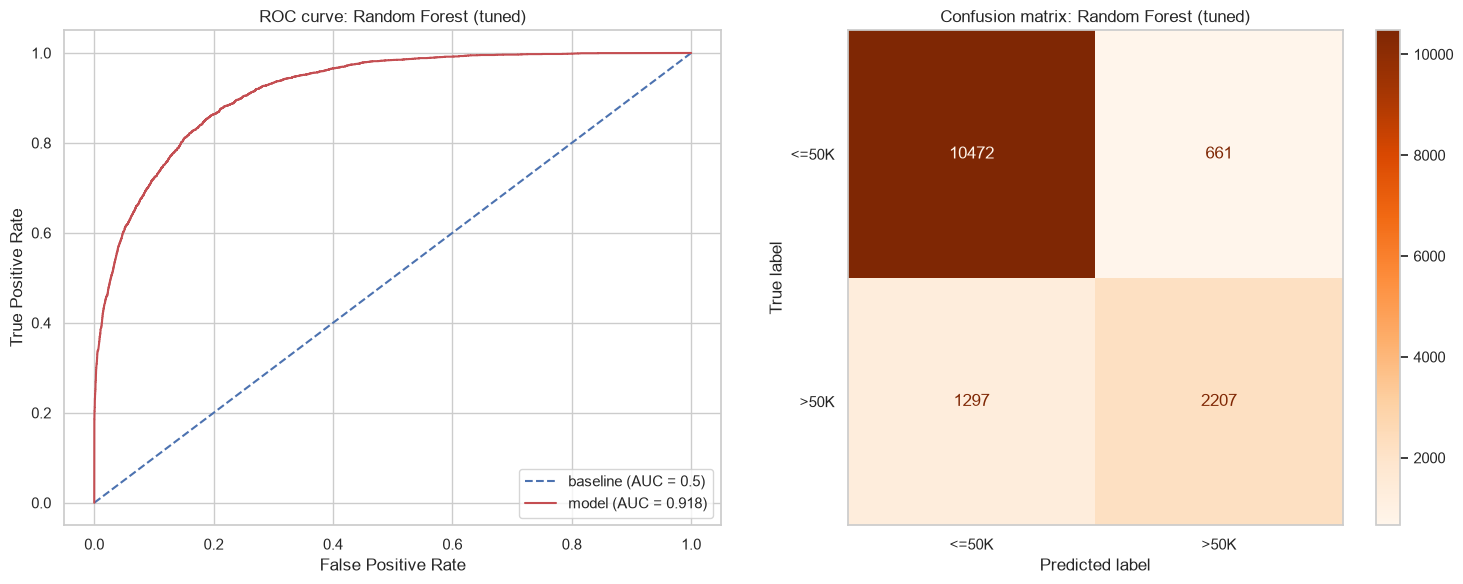

In [38]:
probs['Random Forest (tuned)'] = evaluate_model('Random Forest (tuned)', best_rf)

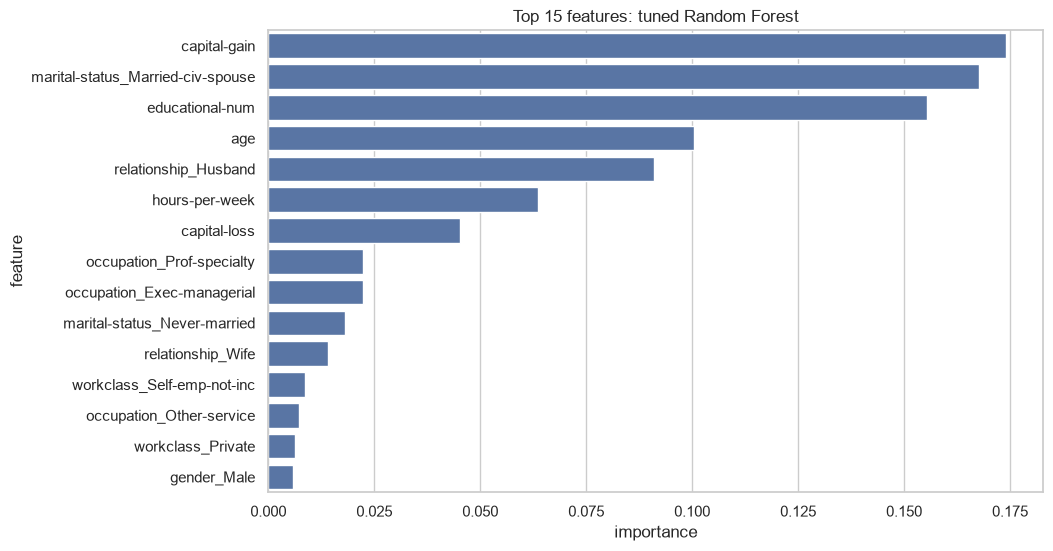

,feature,importance
2,capital-gain,0.174158
16,marital-status_Married-civ-spouse,0.167597
1,educational-num,0.155337
0,age,0.100308
36,relationship_Husband,0.091093
4,hours-per-week,0.063608
3,capital-loss,0.045286
30,occupation_Prof-specialty,0.022435
24,occupation_Exec-managerial,0.022368
18,marital-status_Never-married,0.018076


In [39]:
fi_rf = plot_importances(best_rf, 'Top 15 features: tuned Random Forest')
fi_rf

The forest agrees with the EDA: marital status / relationship, capital gain, education, age and hours per week are the most useful features.

## 7. Model comparison

In [40]:
comparison = pd.DataFrame(results).T
comparison.loc['Baseline (always <=50K)'] = [accuracy_score(test_labels, baseline_pred), 0, 0, 0, 0.5]
comparison.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Decision Tree (unlimited),0.820,0.627,0.613,0.620,0.774
Decision Tree (tuned),0.858,0.756,0.601,0.670,0.907
Random Forest (default),0.847,0.706,0.617,0.658,0.892
Random Forest (tuned),0.866,0.770,0.630,0.693,0.918
Baseline (always <=50K),0.761,0.000,0.000,0.000,0.500


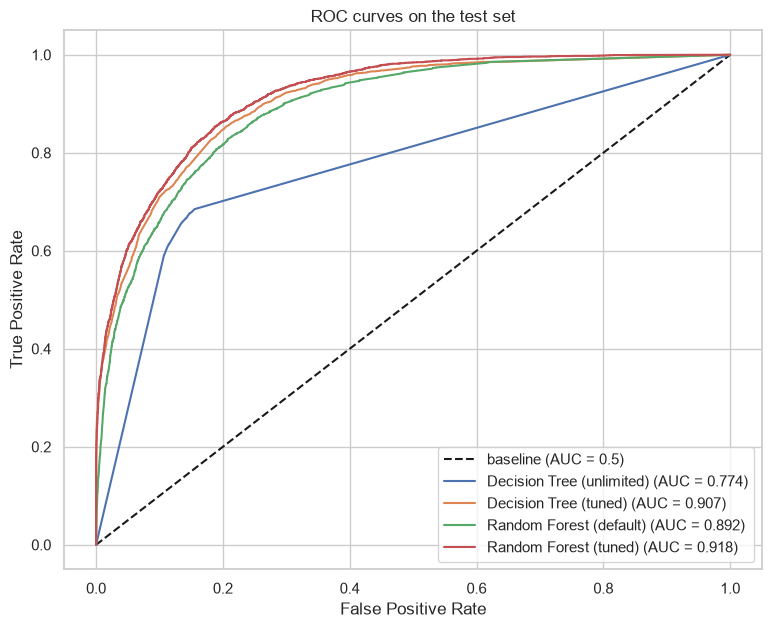

In [41]:
plt.figure(figsize=(9, 7))
plt.plot([0, 1], [0, 1], 'k--', label='baseline (AUC = 0.5)')
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(test_labels, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(test_labels, p):.3f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curves on the test set')
plt.legend()
plt.show()

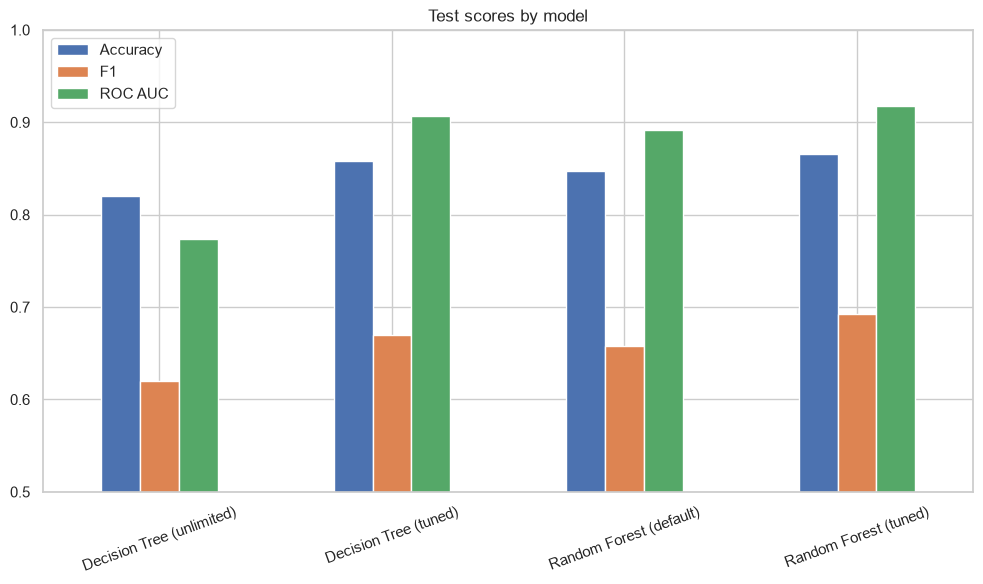

In [42]:
comparison.drop(index='Baseline (always <=50K)')[['Accuracy', 'F1', 'ROC AUC']].plot(kind='bar', figsize=(12, 6))
plt.ylim(0.5, 1)
plt.title('Test scores by model')
plt.xticks(rotation=20)
plt.show()

In [43]:
print(classification_report(test_labels, best_rf.predict(test), target_names=['<=50K', '>50K']))

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.91     11133
        >50K       0.77      0.63      0.69      3504

    accuracy                           0.87     14637
   macro avg       0.83      0.79      0.80     14637
weighted avg       0.86      0.87      0.86     14637



## 8. Conclusions

- **Cleaning:** missing values were hidden as `'?'` in 3 columns; we kept them as an `Unknown` category because missingness itself relates to income. 52 duplicate rows were removed, `education` was dropped as a copy of `educational-num`, and `fnlwgt` was dropped before modelling.
- **EDA:** being married, higher education, older age (up to ~50), more working hours and any capital gain are all linked to earning >50K. The classes are imbalanced (76/24), so accuracy alone is misleading.
- **Decision Tree:** with no depth limit it overfits badly (near-perfect train, much lower test). Limiting depth and leaf size with grid search fixes most of that.
- **Random Forest:** the default forest beats the single unlimited tree (ROC AUC 0.892 vs 0.774), and the tuned forest gives the best test scores of all models (ROC AUC 0.918, accuracy 0.866), confirming the tutorial's main point: averaging many randomised trees reduces variance. A well-tuned single tree (0.907) is also strong on this dataset, so tuning matters as much as the model choice.
- **Weak spot:** recall for the >50K class is only about 0.63 (vs 0.94 for <=50K), because of the imbalance. Lowering the decision threshold or using `class_weight='balanced'` would catch more high earners at the cost of precision.